<a href="https://colab.research.google.com/github/MonishDY/AI-Track/blob/main/Module%204%20-%20Deep%20Learning/Assignment%201/Fashion_MNIST_Case_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Fashion MNIST Classification - Case Study**

## **Fully Connected Neural Networks with TensorFlow/Keras**

### **Dataset Information**
Fashion MNIST contains 70,000 grayscale images of 10 fashion categories:

| Label | Class | Label | Class |
|-------|-------|-------|-------|
| 0 | T-shirt/top | 5 | Sandal |
| 1 | Trouser | 6 | Shirt |
| 2 | Pullover | 7 | Sneaker |
| 3 | Dress | 8 | Bag |
| 4 | Coat | 9 | Ankle boot |

## **Setup: Import Libraries and Load Data**
Run this cell first to set up the environment.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load Fashion MNIST dataset
(train_x, train_y), (test_x, test_y) = tf.keras.datasets.fashion_mnist.load_data()

# Class names for visualization
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print("Dataset loaded successfully!")
print(f"Training samples: {len(train_x)}")
print(f"Test samples: {len(test_x)}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Dataset loaded successfully!
Training samples: 60000
Test samples: 10000


---
## Question 1
**What is the shape of the training dataset (train_x) and what does each dimension represent?**

Print the shape and explain what each dimension means.

In [23]:
# Inspect the training data shape
print("Training dataset shape:", train_x.shape)
print("Each image contains", train_x.shape[1] * train_x.shape[2], "pixel values.")

Training dataset shape: (60000, 28, 28)
Each image contains 784 pixel values.


The shape of the Fashion MNIST training dataset `train_x` is **(60000, 28, 28)**.

- **60000** - Number of training images.
- **28** - Height of each image in pixels.
- **28** - Width of each image in pixels.

*Each image is a 28 x 28 grayscale image representing a fashion item, such as a shirt, shoe, or bag.*

---
## Question 2
**How do you normalize the pixel values of the Fashion MNIST images? Why is normalization important?**

Normalize the pixel values to the range [0, 1] and print the original vs normalized ranges.

In [4]:
# Normalize pixel values to [0, 1]
print("Original pixel range:", train_x.min(), "to", train_x.max())

train_x_norm = train_x.astype("float32") / 255.0
test_x_norm = test_x.astype("float32") / 255.0

print("Normalized training pixel range:", train_x_norm.min(), "to", train_x_norm.max())
print("Normalized test pixel range:", test_x_norm.min(), "to", test_x_norm.max())

Original pixel range: 0 to 255
Normalized training pixel range: 0.0 to 1.0
Normalized test pixel range: 0.0 to 1.0


- Normalize pixel values by dividing them by `255.0`, scaling them from `[0, 255]` to `[0, 1]`.

***Importance:** Normalization improves training stability and helps the model learn faster.*

---
## Question 3
**How do you flatten the 28x28 images to prepare them for a fully connected neural network?**

Show how to flatten the images using both numpy reshape and Keras Flatten layer.

In [24]:
# Flatten images using Numpy
train_x_flat = train_x_norm.reshape(train_x_norm.shape[0], -1)
test_x_flat = test_x_norm.reshape(test_x_norm.shape[0], -1)

print("NumPy flattened training shape:", train_x_flat.shape)
print("NumPy flattened test shape:", test_x_flat.shape)

NumPy flattened training shape: (60000, 784)
NumPy flattened test shape: (10000, 784)


In [26]:
# Flatten images using Keras
flatten_layer = tf.keras.layers.Flatten()
example_flat = flatten_layer(train_x_norm[:1])

print("Keras Flatten output shape for one image:", example_flat.shape)

Keras Flatten output shape for one image: (1, 784)


- Each image is converted into a 784-element vector for the fully connected neural network.

---
## Question 4
**How do you convert the labels to one-hot encoded format? Why is this necessary for classification?**

Convert train_y and test_y to one-hot encoded format and show an example.

In [6]:
# One-hot encode the labels
train_y_onehot = tf.keras.utils.to_categorical(train_y, num_classes=10)
test_y_onehot = tf.keras.utils.to_categorical(test_y, num_classes=10)

print("Original label:", train_y[0])
print("One-hot encoded label:", train_y_onehot[0])
print("One-hot training labels shape:", train_y_onehot.shape)
print("One-hot test labels shape:", test_y_onehot.shape)

Original label: 9
One-hot encoded label: [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
One-hot training labels shape: (60000, 10)
One-hot test labels shape: (10000, 10)


**Importance:** One-hot encoding represents each of the 10 classes as a binary vector, suitable for multiclass classification using categorical cross-entropy.

---
## Question 5
**Build a simple neural network with one hidden layer (128 neurons) for Fashion MNIST classification.**

Create a Sequential model with Flatten, Dense(128, relu), and Dense(10, softmax) layers. Print the model summary.

In [28]:
# Build a neural network with one hidden layer
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_15 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

*The model has one hidden layer with `128 neurons` using ReLU and an output layer with `10 neurons` using Softmax for classification.*

---
## Question 6
**How do you compile the model with an appropriate optimizer, loss function, and metrics?**

Compile the model using Adam optimizer, categorical crossentropy loss, and accuracy metric.

In [29]:
# Compile the model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
print("Model compiled successfully.")

Model compiled successfully.


- **Optimizer:** Adam updates weights efficiently.
- **Loss:** Sparse categorical cross-entropy measures classification error for integer labels.
- **Metric:** Accuracy measures the percentage of correct predictions.

---
## Question 7
**Train the model for 10 epochs and store the training history. What information does the history object contain?**

Train the model with validation_split=0.2 and print the keys in the history object.

In [30]:
# Train for 10 epochs and store the history
history = model.fit(
    train_x_norm,
    train_y_onehot,
    epochs=10,
    validation_split=0.2,
    batch_size=32,
    verbose=1
)

print("\nHistory keys:", history.history.keys())

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8195 - loss: 0.5180 - val_accuracy: 0.8555 - val_loss: 0.4058
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8635 - loss: 0.3861 - val_accuracy: 0.8680 - val_loss: 0.3721
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8731 - loss: 0.3483 - val_accuracy: 0.8712 - val_loss: 0.3619
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8814 - loss: 0.3217 - val_accuracy: 0.8751 - val_loss: 0.3440
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8882 - loss: 0.3030 - val_accuracy: 0.8748 - val_loss: 0.3462
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8951 - loss: 0.2857 - val_accuracy: 0.8852 - val_loss: 0.3281
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8992 - loss: 0.2717 - val_accuracy: 0.8739 - val_loss: 0.3407
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9033 - loss: 0.2590 - 

- The `history` object stores training metrics for each epoch, including training loss, training accuracy, validation loss, and validation accuracy.

---
## Question 8
**How do you evaluate the model on the test dataset and interpret the results?**

Evaluate the model on test data and print the test loss and accuracy.

In [31]:
# Evaluate on the test dataset
test_loss, test_accuracy = model.evaluate(test_x_norm, test_y_onehot, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

Test loss: 0.3655
Test accuracy: 87.19%


- *Test loss measures prediction errors, while test accuracy indicates the percentage of correctly classified images.*
- *Higher accuracy and lower loss indicate better performance.*

---
## Question 9
**How do you make predictions on new images and convert the output to class labels?**

Make predictions on the first 5 test images and compare predicted vs actual classes.

In [32]:
# Predict the first five test images
probabilities = model.predict(test_x_norm[:5], verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)
actual_labels = test_y[:5]

for i in range(5):
    print(
        f"Image {i + 1}: predicted = {class_names[predicted_labels[i]]}, "
        f"actual = {class_names[actual_labels[i]]}"
    )

Image 1: predicted = Ankle boot, actual = Ankle boot
Image 2: predicted = Pullover, actual = Pullover
Image 3: predicted = Trouser, actual = Trouser
Image 4: predicted = Trouser, actual = Trouser
Image 5: predicted = Shirt, actual = Shirt


- `model.predict()` generates class probabilities, and `np.argmax()` converts them into predicted class labels.

---
## Question 10
**Plot the training and validation accuracy curves to visualize model performance over epochs.**

Create two subplots: one for accuracy and one for loss, showing both training and validation curves.

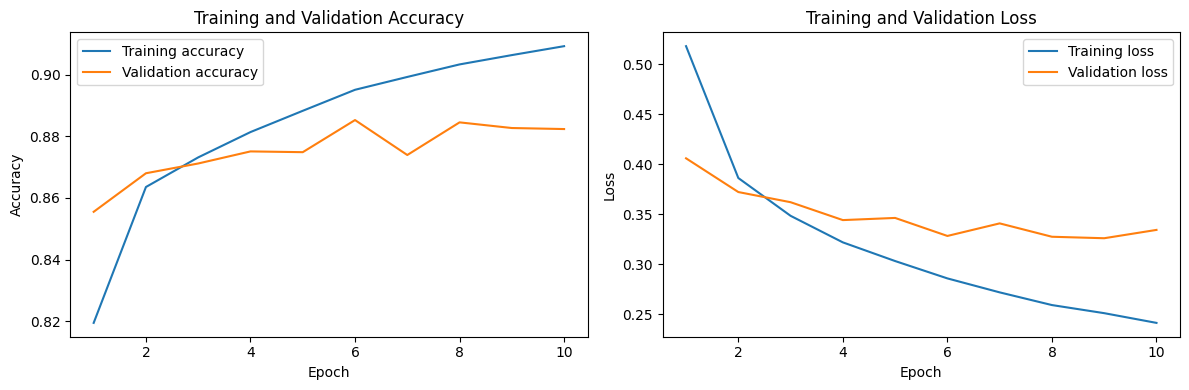

In [33]:
# Plot training/validation accuracy and loss
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"], label="Training accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"], label="Training loss")
plt.plot(epochs_range, history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

### **Analysis**
- Training accuracy reaches 91%, while validation accuracy reaches approximately 89%.
- Training loss decreases steadily, while validation loss gradually stabilizes.
- The model performs well with slight overfitting.

---
## Question 11
**What is the purpose of the activation function in a neural network? Compare ReLU and sigmoid activations.**

Create two models - one with ReLU and one with sigmoid activation in the hidden layer. Train both and compare their performance.

In [36]:
# Compare ReLU and sigmoid hidden-layer activations
def build_activation_model(activation):
    activation_model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation=activation),
        tf.keras.layers.Dense(10, activation="softmax")
    ])
    activation_model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return activation_model

In [35]:
# ReLU
relu_model = build_activation_model("relu")
relu_history = relu_model.fit(
    train_x_norm, train_y_onehot, epochs=5, batch_size=32,
    validation_split=0.2, verbose=1
)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8179 - loss: 0.5212 - val_accuracy: 0.8550 - val_loss: 0.4183
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8614 - loss: 0.3858 - val_accuracy: 0.8698 - val_loss: 0.3725
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8724 - loss: 0.3480 - val_accuracy: 0.8660 - val_loss: 0.3716
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8811 - loss: 0.3245 - val_accuracy: 0.8734 - val_loss: 0.3557
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8874 - loss: 0.3030 - val_accuracy: 0.8775 - val_loss: 0.3419


In [38]:
# Sigmoid
sigmoid_model = build_activation_model("sigmoid")
sigmoid_history = sigmoid_model.fit(
    train_x_norm, train_y_onehot, epochs=5, batch_size=32,
    validation_split=0.2, verbose=1
)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8096 - loss: 0.5724 - val_accuracy: 0.8506 - val_loss: 0.4320
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8556 - loss: 0.4038 - val_accuracy: 0.8615 - val_loss: 0.3818
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8671 - loss: 0.3679 - val_accuracy: 0.8646 - val_loss: 0.3746
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8767 - loss: 0.3418 - val_accuracy: 0.8770 - val_loss: 0.3465
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8822 - loss: 0.3226 - val_accuracy: 0.8732 - val_loss: 0.3433


In [39]:
relu_loss, relu_accuracy = relu_model.evaluate(test_x_norm, test_y_onehot, verbose=0)
sigmoid_loss, sigmoid_accuracy = sigmoid_model.evaluate(test_x_norm, test_y_onehot, verbose=0)

print(f"\nReLU test accuracy: {relu_accuracy:.4f}")
print(f"Sigmoid test accuracy: {sigmoid_accuracy:.4f}")


ReLU test accuracy: 0.8711
Sigmoid test accuracy: 0.8649


- Activation functions introduce non-linearity into neural networks.
- **ReLU:** Outputs `max(0, x)`, is faster, and is commonly used in hidden layers.
- **Sigmoid:** Outputs values between 0 and 1, is useful for binary classification, but may cause vanishing gradients.

### **Analysis**
- ReLU achieves a test accuracy of **87.11%**.
- Sigmoid achieves a test accuracy of **86.49%**.
- ReLU performs slightly better than Sigmoid, with a difference of **0.62 percentage points**.

---
## Question 12
**Build a deeper neural network with two hidden layers (256 and 128 neurons). How does depth affect performance?**

Create a model with two hidden layers, train it, and compare with the single hidden layer model.

In [40]:
# Build and compare a deeper network
deep_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])
deep_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [41]:
deep_history = deep_model.fit(
    train_x_norm, train_y_onehot, epochs=10, batch_size=32,
    validation_split=0.2, verbose=1
)
deep_loss, deep_accuracy = deep_model.evaluate(test_x_norm, test_y_onehot, verbose=0)
single_loss, single_accuracy = model.evaluate(test_x_norm, test_y_onehot, verbose=0)

print(f"\nSingle-hidden-layer test accuracy: {single_accuracy:.4f}")
print(f"Two-hidden-layer test accuracy: {deep_accuracy:.4f}")

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8219 - loss: 0.4947 - val_accuracy: 0.8518 - val_loss: 0.3994
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8627 - loss: 0.3713 - val_accuracy: 0.8649 - val_loss: 0.3704
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8765 - loss: 0.3331 - val_accuracy: 0.8614 - val_loss: 0.3818
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.8861 - loss: 0.3083 - val_accuracy: 0.8761 - val_loss: 0.3495
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8918 - loss: 0.2897 - val_accuracy: 0.8831 - val_loss: 0.3224
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8984 - loss: 0.2714 - val_accuracy: 0.8857 - val_loss: 0.3223
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9028 - loss: 0.2604 - val_accuracy: 0.8840 - val_loss: 0.3291
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9057 - loss: 0.2498 - 

### **Analysis**
- Single-hidden-layer accuracy is **87.19%**.
- Two-hidden-layer accuracy is **87.30%**.
- The deeper network improves accuracy slightly by **0.11%**.
- A deeper model may learn more complex patterns, but performance depends on training and generalization.

---
## Question 13
**What is the softmax activation function and why is it used in the output layer for classification?**

Implement a manual softmax function and demonstrate how it converts logits to probabilities that sum to 1.

In [15]:
# Question 13: Implement softmax manually
def manual_softmax(logits):
    logits = np.asarray(logits, dtype=np.float64)
    exp_values = np.exp(logits - np.max(logits))  # numerical stability
    return exp_values / np.sum(exp_values)

sample_logits = np.array([2.0, 1.0, 0.1])
sample_probabilities = manual_softmax(sample_logits)
print("Logits:", sample_logits)
print("Softmax probabilities:", sample_probabilities)
print("Probability sum:", sample_probabilities.sum())

Logits: [2.  1.  0.1]
Softmax probabilities: [0.65900114 0.24243297 0.09856589]
Probability sum: 1.0


---
## Question 14
**How do you visualize model predictions alongside the actual images?**

Display a 3x3 grid of random test images with their predicted and actual labels. Use green for correct and red for incorrect predictions.

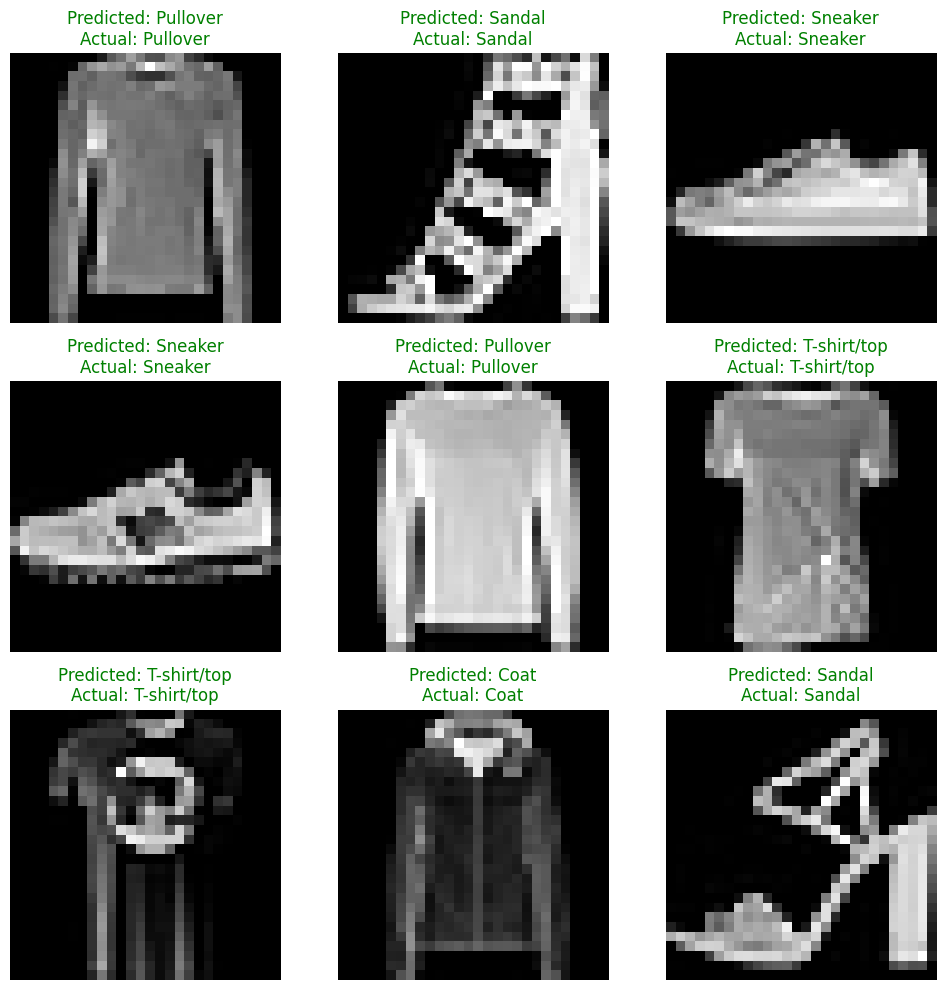

In [16]:
# Question 14: Display nine random test images with predicted and actual labels
random_indices = np.random.default_rng(42).choice(len(test_x_norm), size=9, replace=False)
random_images = test_x_norm[random_indices]
random_probabilities = model.predict(random_images, verbose=0)
random_predictions = np.argmax(random_probabilities, axis=1)

plt.figure(figsize=(10, 10))
for plot_index, data_index in enumerate(random_indices):
    plt.subplot(3, 3, plot_index + 1)
    plt.imshow(test_x[data_index], cmap="gray")
    predicted = random_predictions[plot_index]
    actual = test_y[data_index]
    color = "green" if predicted == actual else "red"
    plt.title(
        f"Predicted: {class_names[predicted]}\nActual: {class_names[actual]}",
        color=color
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

---
## Question 15
**Calculate and display the confusion matrix for model predictions.**

Use sklearn's confusion_matrix and seaborn's heatmap to visualize the results.

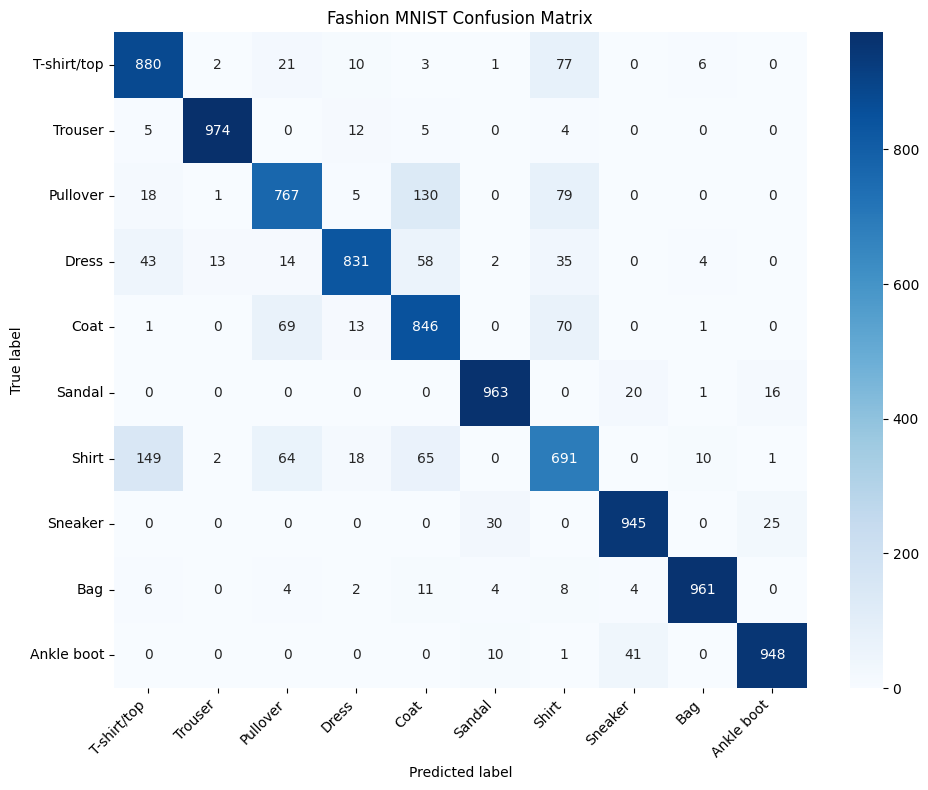

In [17]:
# Question 15: Calculate and plot the confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

test_probabilities = model.predict(test_x_norm, verbose=0)
test_predictions = np.argmax(test_probabilities, axis=1)
cm = confusion_matrix(test_y, test_predictions)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Fashion MNIST Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

---
## Question 16
**What is categorical cross-entropy loss and how is it calculated?**

Implement a manual categorical cross-entropy function and calculate the loss for a sample prediction.

In [18]:
# Question 16: Calculate categorical cross-entropy manually
def manual_categorical_cross_entropy(true_onehot, predicted_probabilities):
    true_onehot = np.asarray(true_onehot, dtype=np.float64)
    predicted_probabilities = np.asarray(predicted_probabilities, dtype=np.float64)
    predicted_probabilities = np.clip(predicted_probabilities, 1e-7, 1.0)
    return -np.mean(np.sum(true_onehot * np.log(predicted_probabilities), axis=1))

sample_true = np.array([[0, 1, 0]])
sample_prediction = np.array([[0.1, 0.7, 0.2]])
sample_loss = manual_categorical_cross_entropy(sample_true, sample_prediction)
print("True one-hot label:", sample_true[0])
print("Predicted probabilities:", sample_prediction[0])
print(f"Manual categorical cross-entropy loss: {sample_loss:.4f}")

True one-hot label: [0 1 0]
Predicted probabilities: [0.1 0.7 0.2]
Manual categorical cross-entropy loss: 0.3567


---
## Question 17
**How do you access and interpret the weights of a trained model?**

Loop through the model layers and print the shape and range of weights for each layer that has weights.

In [19]:
# Question 17: Inspect weights of the trained model
for layer_index, layer in enumerate(model.layers):
    weights = layer.get_weights()
    if weights:
        print(f"Layer {layer_index} ({layer.name}):")
        for weight_index, weight_array in enumerate(weights):
            print(
                f"  Weight array {weight_index}: shape={weight_array.shape}, "
                f"min={weight_array.min():.4f}, max={weight_array.max():.4f}"
            )
    else:
        print(f"Layer {layer_index} ({layer.name}): no trainable weights")

Layer 0 (flatten_1): no trainable weights
Layer 1 (dense):
  Weight array 0: shape=(784, 128), min=-1.2310, max=0.8790
  Weight array 1: shape=(128,), min=-0.4099, max=0.6641
Layer 2 (dense_1):
  Weight array 0: shape=(128, 10), min=-1.6840, max=0.7993
  Weight array 1: shape=(10,), min=-0.4314, max=0.2575


---
## Question 18
**How do you save and load a trained Keras model?**

Save the model to a file, load it back, and verify it works by evaluating on test data.

In [20]:
# Question 18: Save, reload, and evaluate the trained model
model_path = "fashion_mnist_model.keras"
model.save(model_path)
loaded_model = tf.keras.models.load_model(model_path)

loaded_loss, loaded_accuracy = loaded_model.evaluate(test_x_norm, test_y_onehot, verbose=0)
print(f"Saved model to: {model_path}")
print(f"Loaded model test loss: {loaded_loss:.4f}")
print(f"Loaded model test accuracy: {loaded_accuracy:.4f}")

Saved model to: fashion_mnist_model.keras
Loaded model test loss: 0.3404
Loaded model test accuracy: 0.8806


---
## Question 19
**What is the effect of different batch sizes on training? Train with batch sizes 32, 64, and 128.**

Train identical models with different batch sizes and compare their test accuracies.

In [21]:
# Question 19: Compare batch sizes 32, 64, and 128
batch_size_results = {}

def build_batch_comparison_model():
    batch_model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])
    batch_model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return batch_model

for batch_size in [32, 64, 128]:
    print(f"\nTraining with batch size {batch_size}")
    batch_model = build_batch_comparison_model()
    batch_model.fit(
        train_x_norm, train_y_onehot, epochs=5, batch_size=batch_size,
        validation_split=0.2, verbose=1
    )
    _, accuracy = batch_model.evaluate(test_x_norm, test_y_onehot, verbose=0)
    batch_size_results[batch_size] = accuracy

for batch_size, accuracy in batch_size_results.items():
    print(f"Batch size {batch_size}: test accuracy = {accuracy:.4f}")


Training with batch size 32
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8179 - loss: 0.5149 - val_accuracy: 0.8543 - val_loss: 0.4252
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8598 - loss: 0.3872 - val_accuracy: 0.8673 - val_loss: 0.3650
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8742 - loss: 0.3450 - val_accuracy: 0.8678 - val_loss: 0.3674
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8821 - loss: 0.3206 - val_accuracy: 0.8717 - val_loss: 0.3496
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8878 - loss: 0.3018 - val_accuracy: 0.8804 - val_loss: 0.3275

Training with batch size 64
Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8139 - loss: 0.5422 - val_accuracy: 0.8515 - val_loss: 0.4326
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8607 - loss: 0.3969 - val_accuracy: 0.8605 - val_loss: 0.3959
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3

---
## Question 20
**Compare the performance of models with different numbers of neurons in the hidden layer (64, 128, 256, 512).**

Train models with varying hidden layer sizes and create bar plots comparing accuracy and parameter count.


Training model with 64 hidden neurons
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8166 - loss: 0.5364 - val_accuracy: 0.8508 - val_loss: 0.4268
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8550 - loss: 0.4042 - val_accuracy: 0.8611 - val_loss: 0.4012
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8702 - loss: 0.3590 - val_accuracy: 0.8583 - val_loss: 0.3847
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8794 - loss: 0.3354 - val_accuracy: 0.8666 - val_loss: 0.3691
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8826 - loss: 0.3167 - val_accuracy: 0.8780 - val_loss: 0.3417
Test accuracy: 0.8707; parameters: 50,890

Training model with 128 hidden neurons
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8168 - loss: 0.5196 - val_accuracy: 0.8175 - val_loss: 0.4767
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8584 - loss: 0.3904 - val_accuracy: 0.

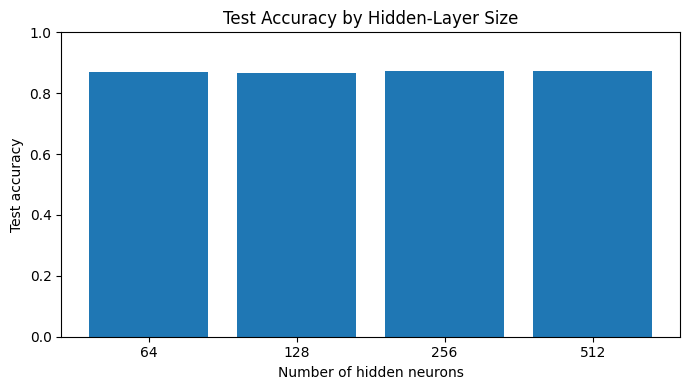

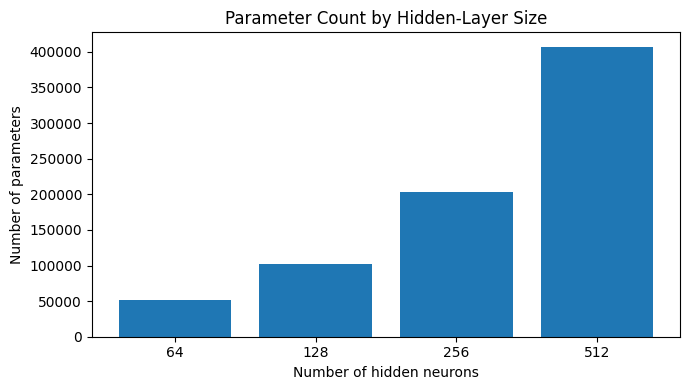

In [22]:
# Question 20: Compare hidden-layer sizes and plot accuracy/parameter count
neuron_results = {}

for neuron_count in [64, 128, 256, 512]:
    print(f"\nTraining model with {neuron_count} hidden neurons")
    neuron_model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(neuron_count, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])
    neuron_model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    neuron_model.fit(
        train_x_norm, train_y_onehot, epochs=5, batch_size=32,
        validation_split=0.2, verbose=1
    )
    _, accuracy = neuron_model.evaluate(test_x_norm, test_y_onehot, verbose=0)
    neuron_results[neuron_count] = {
        "accuracy": accuracy,
        "parameters": neuron_model.count_params()
    }
    print(f"Test accuracy: {accuracy:.4f}; parameters: {neuron_model.count_params():,}")

neuron_counts = list(neuron_results.keys())
accuracies = [neuron_results[n]["accuracy"] for n in neuron_counts]
parameter_counts = [neuron_results[n]["parameters"] for n in neuron_counts]

plt.figure(figsize=(7, 4))
plt.bar([str(n) for n in neuron_counts], accuracies)
plt.xlabel("Number of hidden neurons")
plt.ylabel("Test accuracy")
plt.title("Test Accuracy by Hidden-Layer Size")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.bar([str(n) for n in neuron_counts], parameter_counts)
plt.xlabel("Number of hidden neurons")
plt.ylabel("Number of parameters")
plt.title("Parameter Count by Hidden-Layer Size")
plt.tight_layout()
plt.show()

---
## End of Lab Exercises

Congratulations on completing all 20 exercises! You have learned:
- Data preprocessing and normalization
- Building fully connected neural networks with Keras
- Training, evaluating, and making predictions
- Visualizing results and model performance
- Understanding activation functions, loss functions, and model architecture choices